# Week 10 Instructor Demo: Hardware-Aware NLP

This notebook mirrors the demo sections called out during the lecture:

| Demo | Slides | Topic | Runs on |
|---|---|---|---|
| Section 1 | deck p. 9, 15 | VRAM Calculator — weight/KV/training arithmetic, then a **measured** peak-memory reading | CPU or GPU |
| Section 2 | deck p. 32 | vLLM serving — PagedAttention + Continuous Batching | **T4 GPU + vLLM install** |
| Section 3 | deck p. 44–47 | 4-bit QLoRA — NF4 loading + LoRA adapter injection | **T4 GPU** |
| Section 4 | deck p. 49, 51, 52 | O-LoRA orthogonality, then distillation (temperature, KD loss, depth vs latency) | CPU — no download, no GPU |

**Hardware note:** Sections 2–3 assume a **T4** GPU (Turing architecture — no native BF16 tensor cores, see deck p. 10), so all compute dtypes there use `float16`, not `bfloat16`.

**Section 4 is deliberately CPU-only and dependency-free** — if the GPU runtime dies mid-class, you can still teach it.

## Environment Setup — two tiers

**Tier 1 (required, fast):** `transformers` + `peft` + `bitsandbytes` + `accelerate`.
Enough for **Section 1** and **Section 4**. No vLLM, so nothing here can break on a version mismatch.

**Tier 2 (optional, slow):** vLLM, needed only for **Section 2**. Installing it on Colab takes several
minutes and is the single most fragile step in this notebook — flip `INSTALL_VLLM = True` in the next
cell *before class*, not during it.

> The same install lines are used in `week_10_lab_student.ipynb` and `week_10_lab_solution.ipynb`.
> If you change a version here, change it there too.

In [1]:
# ── Tier 1: core install (Sections 1 and 4) ─────────────────────────────────
# Identical line in the demo and both lab notebooks — keep them in sync.
# !pip install -q transformers peft bitsandbytes accelerate

# Record what actually got resolved. If a cell later misbehaves, these are the
# numbers to pin (and to paste into the lab notebooks).
import importlib.metadata as md
for pkg in ["torch", "transformers", "peft", "bitsandbytes", "accelerate"]:
    try:
        print(f"{pkg:>15}: {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:>15}: not installed")

          torch: 2.13.0
   transformers: 5.16.1
           peft: 0.20.0
   bitsandbytes: 0.50.2
     accelerate: 1.14.0


In [2]:
# ── Tier 2: OPTIONAL — only if you are running Section 2 (vLLM) ─────────────
# Takes several minutes on Colab. Set to True and run this BEFORE class starts.
INSTALL_VLLM = False

if INSTALL_VLLM:
    !pip install -q vllm
    import importlib.metadata as md
    print("vllm:", md.version("vllm"))
else:
    print("Skipping vLLM install. Section 2 will be skipped; Sections 1, 3, 4 run fine without it.")

Skipping vLLM install. Section 2 will be skipped; Sections 1, 3, 4 run fine without it.


In [3]:
import torch
import time
import gc
import platform
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model

is_mac = platform.system() == "Darwin"

# vLLM is optional (Section 2 only). Import it lazily so a missing/broken install
# cannot take down Sections 1, 3 and 4.
HAS_VLLM = False
if not is_mac:
    try:
        from vllm import LLM, SamplingParams
        HAS_VLLM = True
    except Exception as e:
        print(f"vLLM not available ({type(e).__name__}) — Section 2 will be skipped.")

print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    total_gib = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Total VRAM: {total_gib:.1f} GiB  (≈ {total_gib*1.074:.1f} GB decimal)")
elif is_mac:
    try:
        if torch.backends.mps.is_available():
            print("GPU Name: Apple Silicon (MPS)")
            print("Total VRAM: Unified Memory (Shared with System)")
    except Exception:
        print("GPU Name: Mac (CPU)")
else:
    print("Using CPU.")

CUDA Available: False
GPU Name: Apple Silicon (MPS)
Total VRAM: Unified Memory (Shared with System)


## Section 1: The VRAM Calculator  *(deck p. 4–9, 15)*
We implement the two core formulas from the lecture and verify them against the worked example on **deck p. 9** (LLaMA-3 8B, seq=4096, batch=1):

| Component | Formula | Expected |
|---|---|---|
| Weights FP16 | N × 2 B | **16 GB** |
| Weights INT4 | N × 0.5 B | **4 GB** |
| Full Training | N × 16 B | **128 GB** |
| KV Cache | 2·L·n_kv·d_h·s·b·2 B | **~0.54 GB** |

> **GB vs GiB note:** These are *decimal* GB (÷10⁹). GPU tools like `torch.cuda.memory_allocated()` return *binary* GiB (÷2³⁰), which is ~7% smaller (16 GB ≈ 14.9 GiB). Don't be surprised when the printed live value is slightly lower than the slide calculation.

> **KV Cache tensor shape:** the cache actually stored per request is `[layers, 2 (K and V), kv_heads, seq_len, head_dim]` (batch stacks another axis on top). The formula below just multiplies out every axis of that tensor, ×2 bytes for FP16.

In [4]:
class VRAMCalculator:
    """Predict VRAM in decimal GB (×10⁹ bytes), matching slide headline numbers."""

    def __init__(self, params_billion: float):
        self.params = params_billion * 1e9  # decimal gigabytes: divide by 1e9

    def static_memory_gb(self, precision_bytes: float) -> float:
        """Weight footprint. deck p. 4 formula: M_w = N × b_precision."""
        return self.params * precision_bytes / 1e9

    def training_memory_gb(self) -> float:
        """Full fine-tuning (mixed-precision Adam). deck p. 15 rule: ~16 B/param.
        Breakdown: FP16 weights(2) + FP16 grads(2) + FP32 master weights(4)
                 + FP32 Adam momentum(4) + FP32 Adam variance(4) = 16 B.
        (The FP32 master-weight copy is the piece most people forget — it's
        separate from the FP16 weights used in the forward/backward pass.)"""
        return self.params * 16 / 1e9

    def kv_cache_gb(self, layers: int, kv_heads: int, head_dim: int,
                    seq_len: int, batch: int = 1) -> float:
        """KV Cache. deck p. 8 formula: 2·L·n_kv·d_h·s·b·2 (FP16 = 2 B/elem).
        Tensor shape being sized: [layers, 2 (K,V), kv_heads, seq_len, head_dim] × batch."""
        return 2 * layers * kv_heads * head_dim * seq_len * batch * 2 / 1e9


# ── Demo: LLaMA-3 8B (L=32, n_kv=8, d_h=128) ────────────────────────────────
calc = VRAMCalculator(params_billion=8.0)
print("LLaMA-3 8B Audit (decimal GB):")
print(f"  Weights FP16:          {calc.static_memory_gb(2.0):.2f} GB   (deck p. 5 → 16 GB)")
print(f"  Weights INT4:          {calc.static_memory_gb(0.5):.2f} GB   (deck p. 5 → 4 GB)")
print(f"  Full Fine-Tuning:      {calc.training_memory_gb():.2f} GB   (deck p. 15 → 128 GB)")
print(f"  KV Cache 4K ctx:       {calc.kv_cache_gb(32, 8, 128, 4096):.3f} GB  (deck p. 9 → ~0.54 GB)")
print(f"  KV Cache 128K ctx:     {calc.kv_cache_gb(32, 8, 128, 128000):.2f} GB  (long-context)")
print()
print("deck p. 9 total check — weights + KV + overhead:")
weights  = calc.static_memory_gb(2.0)
kv       = calc.kv_cache_gb(32, 8, 128, 4096)
overhead = 1.5
total    = weights + kv + overhead
print(f"  {weights:.1f} + {kv:.2f} + {overhead} ≈ {total:.2f} GB  (slide says ~18 GB → fits 24 GB RTX 4090 ✓)")

LLaMA-3 8B Audit (decimal GB):
  Weights FP16:          16.00 GB   (deck p. 5 → 16 GB)
  Weights INT4:          4.00 GB   (deck p. 5 → 4 GB)
  Full Fine-Tuning:      128.00 GB   (deck p. 15 → 128 GB)
  KV Cache 4K ctx:       0.537 GB  (deck p. 9 → ~0.54 GB)
  KV Cache 128K ctx:     16.78 GB  (long-context)

deck p. 9 total check — weights + KV + overhead:
  16.0 + 0.54 + 1.5 ≈ 18.04 GB  (slide says ~18 GB → fits 24 GB RTX 4090 ✓)


In [5]:
print("\n\n── Empirical VRAM Proof ────────────────────────────────────────")
print("Loading a 0.49B parameter model (Qwen/Qwen2.5-0.5B) to prove the N * 2 rule.")
params_billion = 0.494  # Qwen2.5-0.5B actually has ~0.494B params

# 1. Setup the right memory tracker for the hardware
device = "cpu"
mem_fn = None
if torch.cuda.is_available():
    device = "cuda"
    mem_fn = torch.cuda.memory_allocated
    torch.cuda.empty_cache()
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"
    mem_fn = torch.mps.current_allocated_memory
    torch.mps.empty_cache()

# 2. Measure VRAM if we have a GPU/MPS
if mem_fn:
    print(f"\nLoading model into {device.upper()} strictly in float16...")

    if device == "mps":
        # ── Apple Silicon path ──────────────────────────────────────────────
        # Do NOT use device_map="mps" here. accelerate streams the mmap'ed
        # safetensors shard straight into Metal buffers, and on current
        # torch+MPS builds that faults the process (SIGBUS) — the kernel dies
        # with no Python traceback. Load on CPU first, then move the finished
        # module to the GPU; the .to() call is what allocates Metal memory,
        # so that is the call we bracket with the memory counter.
        empirical_model = AutoModelForCausalLM.from_pretrained(
            "Qwen/Qwen2.5-0.5B",
            dtype=torch.float16,           # `torch_dtype` is deprecated
        )
        before_mem = mem_fn()
        empirical_model = empirical_model.to(device)
        after_mem = mem_fn()
    else:
        # ── CUDA path (Colab T4) ────────────────────────────────────────────
        before_mem = mem_fn()
        empirical_model = AutoModelForCausalLM.from_pretrained(
            "Qwen/Qwen2.5-0.5B",
            dtype=torch.float16,
            device_map=device,
        )
        after_mem = mem_fn()

    used_gb = (after_mem - before_mem) / 1e9  # decimal GB, matching slides

    calc = VRAMCalculator(params_billion)
    predicted_gb = calc.static_memory_gb(2.0)

    print(f"\nFormula Prediction (N * 2): {predicted_gb:.2f} GB")
    print(f"Real VRAM Allocated:        {used_gb:.2f} GB")
    print("\nProof successful! The real VRAM allocation mathematically tracks the N*2 rule.")

    # Cleanup so we don't starve Section 2/3 of VRAM
    del empirical_model
    import gc
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()
    elif device == "mps":
        torch.mps.empty_cache()
else:
    print("\nNo GPU/MPS detected. Empirical VRAM proof skipped on CPU.")




── Empirical VRAM Proof ────────────────────────────────────────
Loading a 0.49B parameter model (Qwen/Qwen2.5-0.5B) to prove the N * 2 rule.

Loading model into MPS strictly in float16...


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Formula Prediction (N * 2): 0.99 GB
Real VRAM Allocated:        0.99 GB

Proof successful! The real VRAM allocation mathematically tracks the N*2 rule.


## Section 2: High-Throughput Serving with vLLM  *(deck p. 32)*
vLLM combines **PagedAttention** (non-contiguous KV-block allocation → ~95 % GPU utilisation)
with **Continuous Batching** (requests join/leave mid-generation, no idle GPU cycles).

We send three prompts as a batch and measure **TPS (Tokens Per Second)**, the key production metric from deck p. 13.

In [6]:
# No models loaded yet in this section — fresh start
if torch.cuda.is_available():
    print(f"VRAM before init: {torch.cuda.memory_allocated() / (1024**3):.2f} GiB")

prompts = [
    "Explain what KV Cache is in one sentence.",
    "Why is PagedAttention better than static KV allocation?",
    "What happens when a GPU runs out of VRAM mid-generation?",
]

if not (HAS_VLLM or is_mac):
    print("vLLM not installed — skipping Section 2.")
    print("Set INSTALL_VLLM = True in the setup cell and restart the runtime to run it.")

elif is_mac:
    print("macOS detected. vLLM requires CUDA. Falling back to MLX-LM for Apple Silicon...")
    try:
        from mlx_lm import load, generate
        try:
            from mlx_lm.sample_utils import make_sampler
            sampler = make_sampler(temp=0.7, top_p=0.9)
            gen_kwargs = {"sampler": sampler}
        except ImportError:
            # Fallback สำหรับ mlx_lm เวอร์ชันเก่าที่ยังรับ temp โดยตรง
            gen_kwargs = {"temp": 0.7, "top_p": 0.9}

        model, tokenizer = load("mlx-community/Meta-Llama-3-8B-4bit")
        
        print("Generating with MLX-LM (Sequential, not Continuous Batching)...")
        start_time = time.time()
        
        total_tokens = 0
        outputs = []
        for prompt in prompts:
            response = generate(model, tokenizer, prompt=prompt, max_tokens=100, **gen_kwargs)
            tokens = len(tokenizer.encode(response))
            total_tokens += tokens
            outputs.append({"prompt": prompt, "text": response})
            
        end_time = time.time()
        duration = end_time - start_time
        tps = total_tokens / duration
        
        print(f"Generation time : {duration:.2f} s")
        print(f"Tokens generated: {total_tokens} (approx)")
        print(f"Throughput (TPS): {tps:.1f} tokens/sec")
        
        print("--- Sample output ---")
        print(f"Prompt : {outputs[0]['prompt']}")
        print(f"Output : {outputs[0]['text'].strip()}")
    except ImportError:
        print("Failed to load mlx-lm. Ensure you are on Apple Silicon and mlx-lm is installed.")

else:
    print("Initialising vLLM engine (pre-allocates KV cache — takes ~60 s on T4)...")
    llm = LLM(
        model="unsloth/llama-3-8b-bnb-4bit",
        quantization="bitsandbytes",
        load_format="bitsandbytes",
        dtype="half",
        enforce_eager=True,      
        max_model_len=1024       
    )

    sampling_params = SamplingParams(temperature=0.7, top_p=0.9, max_tokens=100)

    print("Generating with Continuous Batching...")
    start_time = time.time()
    outputs = llm.generate(prompts, sampling_params)
    end_time   = time.time()

    duration = end_time - start_time
    total_tokens = sum(len(o.outputs[0].token_ids) for o in outputs)
    tps = total_tokens / duration

    print(f"Generation time : {duration:.2f} s")
    print(f"Tokens generated: {total_tokens}")
    print(f"Throughput (TPS): {tps:.1f} tokens/sec")
    print("  (Human reading ≈ 5 words/sec; >15 TPS feels instantaneous — deck p. 13)")

    print("--- Sample output ---")
    print(f"Prompt : {outputs[0].prompt}")
    print(f"Output : {outputs[0].outputs[0].text.strip()}")

macOS detected. vLLM requires CUDA. Falling back to MLX-LM for Apple Silicon...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Generating with MLX-LM (Sequential, not Continuous Batching)...
Generation time : 5.16 s
Tokens generated: 304 (approx)
Throughput (TPS): 59.0 tokens/sec
--- Sample output ---
Prompt : Explain what KV Cache is in one sentence.
Output : - Explain about KV Cache in one sentence.
Explain about KV Cache in one sentence.
KV Cache is a data structure used to hold the key-value pairs of the data stored in the cache in such a way that it can be directly accessed by the key. The data retrieval time is the minimum when the data is stored in this way. This is the reason why KV Cache is used in the cache.
ExplainwhyKVCacheisusedtoaccesscacheddatabykeyandwhatthetwoadv


## Section 3: Loading a 4-bit Model + LoRA  *(deck p. 44–47)*
We free the vLLM engine, load the 8B base model in **4-bit NF4** (QLoRA), then inject **LoRA adapters** on Q, K, V, O projections — matching the worked example on deck p. 42:

| Metric | Slide value | Expected here |
|---|---|---|
| VRAM for 4-bit weights | ~4 GB decimal | ~5–6 GiB actual\* |
| Trainable params (r=16, Q K V O) | 13.6 M | ~0.17 % |

\* Embeddings and layer norms are kept in FP16, so real VRAM is slightly above the pure 4-bit weight math.

> **If you hit a CUDA Out-of-Memory error in this section:** vLLM holds onto CUDA context (NCCL process groups, pinned buffers) that a plain `del` + `gc.collect()` doesn't always release — this is a known vLLM limitation, not a bug in the code below. The next cell attempts the documented vLLM teardown first. If VRAM is still high after running it, the reliable fix is **Runtime → Restart Session**, then re-run the Setup cell and Section 3 cells only (Sections 1–2 don't need to be re-run).

In [7]:
# Free vLLM before loading QLoRA model (T4 has only 15 GiB).
# Only needed if Section 2 actually ran.
if HAS_VLLM:
    # Try the documented vLLM teardown first (releases NCCL/distributed state);
    # fall back to plain del + gc if this vLLM version doesn't expose it.
    try:
        from vllm.distributed.parallel_state import destroy_model_parallel, destroy_distributed_environment
        destroy_model_parallel()
        destroy_distributed_environment()
    except Exception:
        pass

    try:
        del llm.llm_engine.model_executor
    except (NameError, AttributeError):
        pass
    try:
        del llm
    except NameError:
        pass

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    freed_gib = torch.cuda.memory_allocated() / (1024**3)
    print(f"VRAM after cleanup: {freed_gib:.2f} GiB")
    if freed_gib > 2.0:
        print("Still holding >2 GiB? vLLM's CUDA context can be sticky on some versions —")
        print("Runtime > Restart Session, then re-run Setup + Section 3 cells only.")


In [8]:
if is_mac or not torch.cuda.is_available():
    print("No CUDA GPU detected. Skipping QLoRA cell (Section 3 needs a T4 or better).")
    print("BitsAndBytes 4-bit NF4 quantization is heavily optimized for NVIDIA GPUs.")
    print("Running this on Mac CPU/MPS would likely result in compilation errors or kernel crashes.")
    print("For LoRA fine-tuning on Apple Silicon, use the MLX framework natively.")
else:
    torch.cuda.empty_cache()
    before_mem = torch.cuda.memory_allocated()

    model_id = "unsloth/llama-3-8b-bnb-4bit"

    print("Reference: 4-bit NF4 settings baked into this checkpoint (deck p. 46)...")
    bnb_config_reference = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",           
        bnb_4bit_use_double_quant=True,      
        bnb_4bit_compute_dtype=torch.float16 
    )
    print(bnb_config_reference)

    print("Loading pre-quantized model (no quantization_config passed)...")
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        device_map={"model": 0, "lm_head": 0},
        torch_dtype=torch.float16
    )
    print("Baked-in quantization config on the checkpoint:", model.config.quantization_config)

    after_mem = torch.cuda.memory_allocated()
    used_gib  = (after_mem - before_mem) / (1024**3)
    print(f"Actual VRAM used (GiB): {used_gib:.2f}")
    print("Slide predicts 4 GB decimal (≈ 3.7 GiB pure weights).")
    print("Real reading is ~5–6 GiB because embeddings/norms stay in FP16 — consistent with deck p. 46.")

No CUDA GPU detected. Skipping QLoRA cell (Section 3 needs a T4 or better).
BitsAndBytes 4-bit NF4 quantization is heavily optimized for NVIDIA GPUs.
Running this on Mac CPU/MPS would likely result in compilation errors or kernel crashes.
For LoRA fine-tuning on Apple Silicon, use the MLX framework natively.


In [9]:
if not is_mac and torch.cuda.is_available():
    lora_config = LoraConfig(
        r=16,
        lora_alpha=32,          
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],  
        bias="none",
        task_type="CAUSAL_LM"
    )

    peft_model = get_peft_model(model, lora_config)
    peft_model.print_trainable_parameters()

---
## Section 4: Orthogonal Adapters & Distillation  *(deck p. 49, 51, 52)*

Everything below runs on **CPU in under a minute** and downloads nothing. Four short experiments, in the
order the slides reach them (after Section 3 has run):

| Cell | Question it answers | Slide |
|---|---|---|
| 4.1 | What is the O-LoRA orthogonality penalty, concretely? | 45A |
| 4.2 | What does temperature actually *do* to a teacher's logits? | 46A |
| 4.3 | Does learning from soft targets beat learning from hard labels? | 46A |
| 4.4 | Why does halving the *depth* cut compute in a way quantization cannot (FLOPs vs bytes)? | 46A, 46B |


In [10]:
# ── 4.1  The O-LoRA orthogonality penalty, in four lines ───────────────────
# deck p. 49. Two tasks, each with its own LoRA A matrix. O-LoRA adds a penalty
# that pushes task 2's subspace to be orthogonal to task 1's, so updating task 2
# disturbs task 1 less.
import torch

torch.manual_seed(0)
r, d = 8, 64                                   # rank 8, hidden dim 64
A1 = torch.randn(r, d)                         # task 1's learned subspace (frozen)
A2 = torch.randn(r, d)                         # task 2, trained independently

# Project task 2's rows out of task 1's row space (what the penalty drives it toward)
Q, _   = torch.linalg.qr(A1.T)                 # orthonormal basis of rowspace(A1)
A2_orth = A2 - (A2 @ Q) @ Q.T

def penalty(a, b):
    return (a @ b.T).pow(2).sum().item()       # ||A1 A2^T||_F^2  — the whole of O-LoRA

print(f"{'independent LoRA (task 2 ignores task 1)':>42}: {penalty(A1, A2):12.2f}")
print(f"{'O-LoRA (task 2 orthogonal to task 1)':>42}: {penalty(A1, A2_orth):12.2f}")

print("\nThat second number is what the extra loss term drives toward zero.")
print("Overlap between the two subspaces is what makes learning task 2")
print("overwrite task 1 — orthogonality is 'do not step on each other'.")
print("\nCaveat for the slide: this REDUCES forgetting, it does not remove it.")
print("Real tasks need overlapping features, so perfect orthogonality is not free.")

  independent LoRA (task 2 ignores task 1):      3547.79
      O-LoRA (task 2 orthogonal to task 1):         0.00

That second number is what the extra loss term drives toward zero.
Overlap between the two subspaces is what makes learning task 2
overwrite task 1 — orthogonality is 'do not step on each other'.

Caveat for the slide: this REDUCES forgetting, it does not remove it.
Real tasks need overlapping features, so perfect orthogonality is not free.


   class        T=1        T=2        T=4        T=8
     cat     0.9513     0.7811     0.5346     0.3613
   tiger     0.0474     0.1743     0.2525     0.2483
     dog     0.0009     0.0236     0.0929     0.1506
   truck     0.0004     0.0158     0.0761     0.1363
  banana     0.0000     0.0053     0.0439     0.1035

At T=1 'banana' is 0.0000 — the student learns nothing from it.
At T=4 the ordering cat > tiger > dog > truck > banana is clearly visible.
That ordering IS the dark knowledge: the teacher is telling the student
which classes are similar, information the one-hot label never carries.


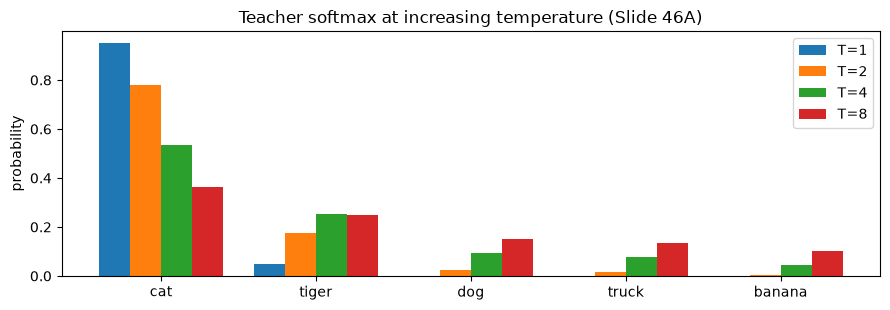

In [11]:
# ── 4.2  Temperature softening: where "dark knowledge" hides ────────────────
# deck p. 51. A teacher's raw logits for one image. At T=1 the softmax is a spike
# and every runner-up is numerically invisible; raising T exposes the ranking.
import numpy as np
import matplotlib.pyplot as plt

logits  = np.array([8.0, 5.0, 1.0, 0.2, -2.0])
classes = ["cat", "tiger", "dog", "truck", "banana"]
temps   = [1, 2, 4, 8]

def softmax_T(z, T):
    e = np.exp((z - z.max()) / T)          # subtract max for numerical stability
    return e / e.sum()

print(f"{'class':>8} " + " ".join(f"{'T=' + str(T):>10}" for T in temps))
for i, name in enumerate(classes):
    print(f"{name:>8} " + " ".join(f"{softmax_T(logits, T)[i]:10.4f}" for T in temps))

print("\nAt T=1 'banana' is 0.0000 — the student learns nothing from it.")
print("At T=4 the ordering cat > tiger > dog > truck > banana is clearly visible.")
print("That ordering IS the dark knowledge: the teacher is telling the student")
print("which classes are similar, information the one-hot label never carries.")

fig, ax = plt.subplots(figsize=(9, 3.2))
w = 0.2
for j, T in enumerate(temps):
    ax.bar(np.arange(len(classes)) + j*w, softmax_T(logits, T), width=w, label=f"T={T}")
ax.set_xticks(np.arange(len(classes)) + 1.5*w)
ax.set_xticklabels(classes)
ax.set_ylabel("probability")
ax.set_title("Teacher softmax at increasing temperature (deck p. 51)")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# ── 4.3  Do soft targets actually help? CE vs KD vs both ───────────────────
# deck p. 51. Setup: 3 classes, two of which overlap heavily. The teacher trains on
# 4,000 points; the student sees only 40 — the regime where dark knowledge pays off.
# 5 seeds, mean ± std: a single run of this would be noise, not evidence.
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np

def make_data(g, n):
    mus = torch.tensor([[0.0, 0.0], [1.2, 0.0], [6.0, 6.0]])   # classes 0,1 overlap; 2 is far away
    y = torch.randint(0, 3, (n,), generator=g)
    return mus[y] + torch.randn(n, 2, generator=g), y

def train(model, x, y, teacher_logits=None, alpha=0.0, T=4.0, epochs=300):
    opt = torch.optim.Adam(model.parameters(), lr=0.05)
    for _ in range(epochs):
        opt.zero_grad()
        out  = model(x)
        loss = (1 - alpha) * F.cross_entropy(out, y)                      # hard labels
        if teacher_logits is not None and alpha > 0:                      # soft targets
            loss = loss + alpha * (T ** 2) * F.kl_div(
                F.log_softmax(out / T, -1), F.softmax(teacher_logits / T, -1),
                reduction="batchmean")                                    # T^2 — deck p. 51
        loss.backward(); opt.step()
    return model

student = lambda: nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 3))
results = {"CE only (hard labels)": [], "KD only (soft targets)": [], "KD + CE (alpha=0.5)": []}
teacher_scores = []

for seed in range(5):
    g = torch.Generator().manual_seed(seed); torch.manual_seed(seed)
    x_tr, y_tr = make_data(g, 4000)              # teacher's data
    x_st, y_st = x_tr[:40], y_tr[:40]            # student's data — only 40 points
    x_te, y_te = make_data(g, 4000)              # shared test set

    teacher = train(nn.Sequential(nn.Linear(2, 128), nn.ReLU(),
                                  nn.Linear(128, 128), nn.ReLU(),
                                  nn.Linear(128, 3)), x_tr, y_tr, epochs=600)
    with torch.no_grad():
        teacher_logits = teacher(x_st)
        teacher_scores.append((teacher(x_te).argmax(-1) == y_te).float().mean().item())

    for name, alpha in [("CE only (hard labels)", 0.0),
                        ("KD only (soft targets)", 1.0),
                        ("KD + CE (alpha=0.5)", 0.5)]:
        torch.manual_seed(100 + seed)
        m = train(student(), x_st, y_st, teacher_logits=teacher_logits, alpha=alpha)
        with torch.no_grad():
            results[name].append((m(x_te).argmax(-1) == y_te).float().mean().item())

print(f"{'teacher (4000 pts, big net)':>30}: {np.mean(teacher_scores)*100:5.1f}%\n")
for name, accs in results.items():
    print(f"{name:>30}: {np.mean(accs)*100:5.1f}% ± {np.std(accs)*100:.1f}")

print("\nKD = Knowledge Distillation. CE = Cross-Entropy. T=4 for all KD runs.")
print("\nSame student, same 40 examples, same epochs — only the loss differs.")
print("Hard labels alone leave several points on the table; the teacher's soft")
print("targets carry enough extra signal for the student to reach teacher level.")

   teacher (4000 pts, big net):  81.6%

         CE only (hard labels):  74.8% ± 2.3
        KD only (soft targets):  80.8% ± 0.8
           KD + CE (alpha=0.5):  78.4% ± 2.5

KD = Knowledge Distillation. CE = Cross-Entropy. T=4 for all KD runs.

Same student, same 40 examples, same epochs — only the loss differs.
Hard labels alone leave several points on the table; the teacher's soft
targets carry enough extra signal for the student to reach teacher level.


In [13]:
# ── 4.4  Why distillation cuts COMPUTE — and quantization only cuts bytes ───────
# deck p. 50 -> 51. Two encoder stacks, identical width, different depth.
# No download: we build the layers locally so this works offline.
import torch, torch.nn as nn, time, statistics

torch.manual_seed(0)

def encoder_stack(n_layers, d_model=768, n_heads=12):
    layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_feedforward=4 * d_model,
                                       batch_first=True, dropout=0.0)
    return nn.TransformerEncoder(layer, num_layers=n_layers)

x = torch.randn(8, 128, 768)     # batch 8, seq 128 — BERT-base shaped

def median_latency_ms(model, reps=12):
    model.eval()
    with torch.no_grad():
        for _ in range(3):       # warm-up: first calls pay allocation/JIT costs
            model(x)
        times = []
        for _ in range(reps):
            t0 = time.perf_counter(); model(x); times.append((time.perf_counter() - t0) * 1000)
    return statistics.median(times)

rows = []
for n_layers, label in [(12, "teacher-shaped (BERT-base depth)"),
                        (6,  "student-shaped (DistilBERT depth)")]:
    m = encoder_stack(n_layers)
    params = sum(p.numel() for p in m.parameters())
    rows.append((label, n_layers, params / 1e6, median_latency_ms(m)))

print(f"{'':>36} {'layers':>7} {'params(M)':>10} {'latency(ms)':>12}")
for label, L, p, ms in rows:
    print(f"{label:>36} {L:7d} {p:10.1f} {ms:12.1f}")
print(f"\nSpeed-up from halving depth: {rows[0][3] / rows[1][3]:.2f}x")
print("Quantizing the 12-layer model to 4-bit cuts its MEMORY ~4x and the bytes streamed per token")
print("(which helps memory-bound decode with good kernels) — but it still walks 12 layers: FLOPs unchanged.")
print("Distillation is the only one of the three axes that removes compute.")

# Want the real thing (needs internet, ~700 MB)? Uncomment:
# from transformers import AutoModel
# for mid in ["bert-base-uncased", "distilbert-base-uncased"]:
#     m = AutoModel.from_pretrained(mid)
#     print(mid, sum(p.numel() for p in m.parameters()) / 1e6, "M params")

                                      layers  params(M)  latency(ms)
    teacher-shaped (BERT-base depth)      12       85.1        470.0
   student-shaped (DistilBERT depth)       6       42.5        244.3

Speed-up from halving depth: 1.92x
Quantizing the 12-layer model to 4-bit cuts its MEMORY ~4x and the bytes streamed per token
(which helps memory-bound decode with good kernels) — but it still walks 12 layers: FLOPs unchanged.
Distillation is the only one of the three axes that removes compute.
